## **ЛР №2 — кластеризации методом K-means (k-средних)**.

Для кластеризации используем набор данных «Леденцы», содержащий оценки потребителей по 11 признакам (V1–V11). Исследуем размер таблицы и проверим наличие пропущенных значений.

В наборе 338 наблюдений, все признаки числовые и имеют одинаковую шкалу. Пропусков нет, поэтому дополнительная обработка данных не требуется.

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Леденцы.dat', sep=';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [30]:
df.shape
df.isnull().sum()

,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


**Выбор числа кластеров**

Для метода K-means необходимо заранее задать количество кластеров. Проверим значения k от 2 до 10 и рассчитаем для каждого разбиения коэффициент силуэта. Он позволяет оценить, насколько близки объекты внутри своих групп и насколько хорошо группы отделены друг от друга.

Для воспроизводимости результатов используем random_state=42. Параметр n_init=10 задает десять запусков алгоритма с разными начальными центрами.В

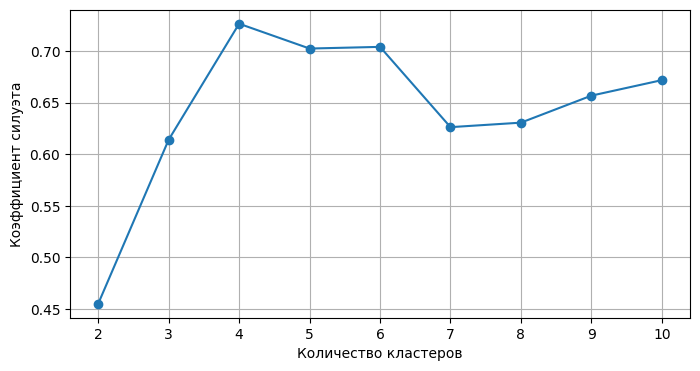

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

# Проверяем кол-во
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(df)
    scores.append(silhouette_score(df, labels))

# График коэффициента силуэта
plt.figure(figsize=(8, 4))
plt.plot(range(2, 11), scores, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.xticks(range(2, 11))
plt.grid()
plt.show()

Максимальный коэффициент силуэта получен при k = 4 и составляет 0,727. При дальнейшем увеличении числа кластеров показатель снижается. Поэтому предварительно выбрано разбиение на четыре группы. Дополнительно проверим этот выбор методом локтя.

### Метод локтя

Метод локтя помогает выбрать количество кластеров K. Для каждого K рассчитывается инерция — сумма квадратов расстояний объектов до центроидов своих кластеров.

При увеличении K инерция уменьшается. На графике ищем точку, после которой снижение становится заметно слабее.

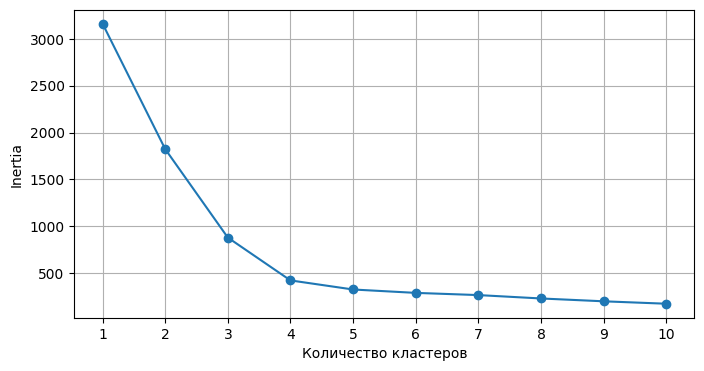

In [32]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

# Проверяем от 1 до 10 кластеров
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(df)
    inertia.append(model.inertia_)

# Строим график метода локтя
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid()
plt.show()

На графике заметное изменение наклона происходит при k = 4. После этого значения Inertia уменьшается значительно медленнее. Таким образом, метод локтя подтверждает результат, полученный по коэффициенту силуэта. Для дальнейшей кластеризации выбираем 4 кластера.

### Кластеризация методом K-means

Выполним кластеризацию с выбранным значением k = 4. Алгоритм распределит респондентов по ближайшим центрам кластеров и последовательно пересчитает их положения до сходимости.

После кластеризации определим численность каждой группы и рассмотрим координаты центров по 11 исходным признакам.

In [33]:

# Кластеризация на 4 группы
model = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = model.fit_predict(df)

# Количество респондентов в каждом кластере
pd.Series(labels).value_counts().sort_index()


,count
0,108
1,61
2,110
3,59


In [34]:

# Центры кластеров
centers = pd.DataFrame(model.cluster_centers_, columns=df.columns)
centers.round(2)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
1,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00


Для визуализации полученных кластеров снизим размерность данных до двух главных компонент с помощью PCA. На графике отобразим респондентов по принадлежности к кластерам и центры групп, рассчитанные методом K-means.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


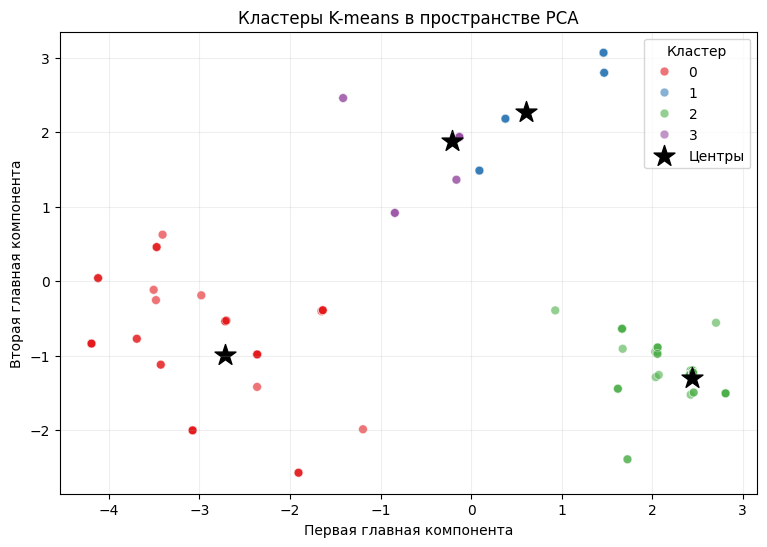

In [35]:

from sklearn.decomposition import PCA
import seaborn as sns

# Снижаем размерность до двух компонент
pca = PCA(n_components=2)
x = pca.fit_transform(df)

# Переводим центры в те же координаты
c = pca.transform(model.cluster_centers_)

# Строим график кластеров
plt.figure(figsize=(9, 6))
sns.scatterplot(x=x[:, 0], y=x[:, 1],
                hue=labels, palette='Set1',
                s=40, alpha=0.6)

plt.scatter(c[:, 0], c[:, 1], marker='*',
            s=250, c='black', label='Центры')

plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Кластеры K-means в пространстве PCA')
plt.legend(title='Кластер')
plt.grid(alpha=0.2)
plt.show()


In [36]:
pca.explained_variance_ratio_.sum()

np.float64(0.7798351988951506)

In [37]:
# Итоговая модель с 4 кластерами
model = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = model.fit_predict(df)

In [38]:
import numpy as np

# Расстояния объектов до своих центроидов
distances = np.linalg.norm(
    df.to_numpy() - model.cluster_centers_[labels],
    axis=1
)

# Среднее расстояние для каждого кластера
pd.DataFrame({
    'Кластер': labels,
    'Расстояние': distances
}).groupby('Кластер').mean().round(2)

,Расстояние
Кластер,
0,1.39
1,0.83
2,0.85
3,0.37


In [39]:
from sklearn.metrics import pairwise_distances

# Расстояния между центроидами
center_distances = pairwise_distances(
    model.cluster_centers_,
    metric='euclidean'
)

pd.DataFrame(center_distances).round(2)

,0,1,2,3
0,0.00,4.90,5.19,4.43
1,4.90,0.00,4.44,3.90
2,5.19,4.44,0.00,4.56
3,4.43,3.90,4.56,0.00


Для анализа полученных групп построим тепловую карту центров кластеров. Она показывает средние значения признаков V1–V11 и позволяет определить, какие мотивы потребления наиболее выражены в каждой группе.

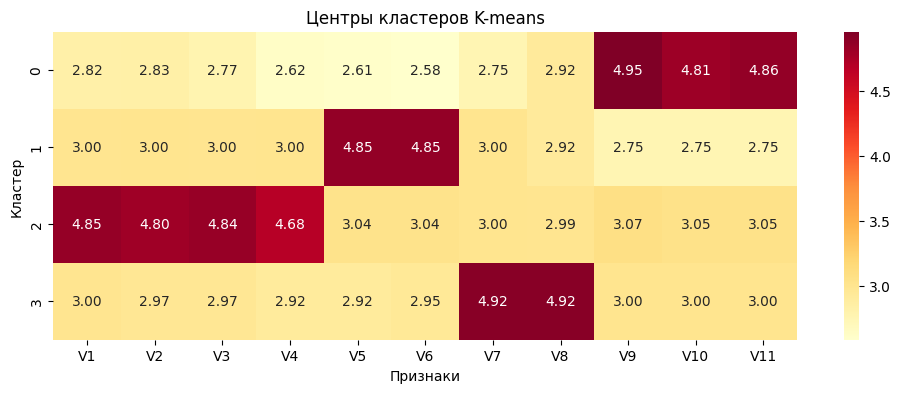

In [40]:
import seaborn as sns

# Тепловая карта центров кластеров
plt.figure(figsize=(12, 4))
sns.heatmap(centers, annot=True, fmt='.2f', cmap='YlOrRd')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.title('Центры кластеров K-means')
plt.show()

**Интерпретация кластеров**

По результатам кластеризации выделены четыре группы потребителей:

Кластер 0 (108 человек): преобладают лечебные мотивы, связанные с облегчением боли в горле, заложенности носа и улучшением самочувствия (V9–V11).

Кластер 1 (61 человек): употребление леденцов как сладости или замены другим кондитерским изделиям (V5–V6).

Кластер 2 (110 человек): потребление для освежения дыхания, полости рта и устранения неприятного вкуса (V1–V4).

Кластер 3 (59 человек): употребление для концентрации внимания и кратковременного отвлечения (V7–V8).

Наиболее выраженные мотивы различаются между группами, что позволяет содержательно интерпретировать полученные кластеры.

### Вывод

В работе проведена кластеризация 338 респондентов по 11 признакам методом K-means. Количество кластеров определено с помощью коэффициента силуэта и метода локтя. Оба способа показали целесообразность выбора k = 4. Коэффициент силуэта при этом составил 0,727.

Получены четыре группы численностью 108, 61, 110 и 59 человек. Анализ центров кластеров показал различия в основных мотивах употребления леденцов: облегчение симптомов заболеваний, желание сладкого, освежение дыхания, концентрация и отвлечение.

Полученные кластеры имеют достаточно четкие различия по исходным признакам и могут быть использованы для сегментации потребителей.